# Step 5. Baseline Model
## Контрольная система: CM → бюджет → возраст → FIFA overall → TOP-5

**Сценарий:** клуб ищет одного центрального полузащитника с бюджетом **€15 млн**. Максимальный возраст для демонстрации — **30,0 лет** на дату среза **26.09.2022**. Все параметры изменяются в следующей ячейке.

Алгоритм:
1. Оставить игроков, у которых отдельный токен `CM` присутствует среди позиций.
2. Оставить записанную стоимость ≤15 000 000.
3. Оставить возраст на cutoff ≤30,0 лет.
4. Отсортировать по `overall` по убыванию.
5. Вернуть до пяти игроков.

При равном overall: меньшая стоимость, затем строковый fifa_id по возрастанию. Это только разрешение равенств, а не дополнительный обучаемый скоринг.

**TOP-5 — альтернативы для одной покупки**, а не состав из пяти игроков с общей стоимостью ≤15 млн. Общий рейтинг не означает вероятность успешного трансфера.

Никаких fit, scaler, кластеров, предсказаний цены или similarity внутри baseline нет. Реализация доступна отдельно в [src/baseline.py](../src/baseline.py). Контроль фиксируется после исследовательского EDA, до основного сравнения рекомендательных систем; не заявляем, что он предшествовал всем исследовательским ML-экспериментам.


In [1]:
from pathlib import Path
import hashlib
import inspect
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
%matplotlib inline

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config/feature_set_v1.json").exists())
sys.path.insert(0, str(ROOT))
from src.baseline import build_eligible_pool, select_baseline, RANK_COLUMNS

BUDGET = 15_000_000
MAX_AGE = 30.0
TOP_K = 5
CUTOFF = "2022-09-26"
MAX_VALUE_AGE_DAYS = 365
EXCLUDED_FIFA_IDS = []  # comparison by reference player: exclude the same ID in both methods
CURRENCY_ASSUMPTION = "EUR"
CURRENCY_STATUS = "assumed_for_scenario_not_verified_in_TM_archive"
INPUT = ROOT / "data/processed/preprocessing"
OUT = ROOT / "data/processed/baseline"
REPORT = ROOT / "reports/baseline"
OUT.mkdir(parents=True, exist_ok=True)
REPORT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.family": "DejaVu Sans", "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False})
figures = []

def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def ids_hash(ids):
    return hashlib.sha256("\n".join(sorted(map(str,ids))).encode()).hexdigest()

def show(fig, name):
    for extension in ["png", "svg"]:
        path=REPORT/f"{name}.{extension}"
        fig.savefig(path,dpi=170,bbox_inches="tight",facecolor="white")
        if extension=="svg":
            path.write_text("\n".join(line.rstrip() for line in path.read_text(encoding="utf-8").splitlines())+"\n",encoding="utf-8")
    figures.append(name)
    plt.show(); plt.close(fig)

PARAMS = dict(max_value=BUDGET, max_age=MAX_AGE, top_k=TOP_K, cutoff=CUTOFF,
              max_value_age_days=MAX_VALUE_AGE_DAYS, excluded_fifa_ids=EXCLUDED_FIFA_IDS)
display(pd.DataFrame({"parameter":list(PARAMS)+["currency_assumption","currency_status"],
                      "value":[str(v) for v in PARAMS.values()]+[CURRENCY_ASSUMPTION,CURRENCY_STATUS]}))


,parameter,value
0,max_value,15000000
1,max_age,30.0
2,top_k,5
3,cutoff,2022-09-26
4,max_value_age_days,365
5,excluded_fifa_ids,[]
6,currency_assumption,EUR
7,currency_status,assumed_for_scenario_not_verified_in_TM_archive


### 1. Исторический источник и денежные единицы

Основной пул — **2 886 CM**, подготовленных в Step 2: мужчины FIFA 23 с положительной оценкой TM на дату или раньше cutoff, давностью ≤365 дней. Исходные 4 184 FIFA CM не все имеют пригодную связанную стоимость, поэтому baseline и ML нужно сравнивать в одном покрытом пуле.

Используем **TM market value**, а не игровую цену FIFA и не фактический transfer fee. Архив TM не содержит подтверждения денежной единицы. Для сценария пользователя явно принимаем **EUR как допущение**; преобразования валют не выполняются и название исходного столбца `tm_market_value` сохраняется. До реального бюджетного решения единицы и полная стоимость сделки должны быть проверены.

Возраст дробный, вычислен по дате рождения: ≤30 означает не старше ровно 30,0 лет; игроку 30,5 лет фильтр не пройти. Значения на самой границе бюджета и возраста включаются.


In [2]:
manifest = json.loads((INPUT/"dataset_manifest.json").read_text(encoding="utf-8"))
source = INPUT/manifest["dataset"]
assert sha(source)==manifest["sha256"]
players = pd.read_csv(source,dtype={"fifa_id":str,"tm_id":str,"league_id":str})
assert players.fifa_id.is_unique and players.tm_id.is_unique
assert players.as_of_date.eq(CUTOFF).all() and players.fifa_update_date.eq(CUTOFF).all()
assert players.market_value_date.le(CUTOFF).all()
display(players[["short_name","player_positions_normalized","age_at_cutoff","overall","tm_market_value","market_value_date"]].head())
print("Source:",manifest["dataset"],"; rows:",len(players))
print("В исходном пуле CM уже отобраны в Step 2; повторный фильтр CM остаётся частью алгоритма.")


Source: moneyball_cm_2022-09-26_clean.csv ; rows: 2886
В исходном пуле CM уже отобраны в Step 2; повторный фильтр CM остаётся частью алгоритма.


,short_name,player_positions_normalized,age_at_cutoff,overall,tm_market_value,market_value_date
0,A. Hutchinson,CM|CDM,39.631204,72,275000.0,2022-05-31
1,C. Lepoint,CDM|CB|CM,37.922750,67,75000.0,2022-04-18
2,J. Milner,CM|LB|RB,36.726285,78,2000000.0,2022-06-14
3,B. Džemaili,CM|CDM,36.457970,71,200000.0,2022-06-07
4,Aitor Sanz,CM|CDM,38.035004,72,100000.0,2022-06-28


### 2. Простой алгоритм и независимая сверка пяти шагов

Дополнительные проверки качества не являются моделью: неподтверждённая/нулевая цена, пропущенный возраст/рейтинг, будущие/устаревшие оценки не допускаются. Дубли ID вызывают ошибку вместо произвольного выбора строки. При отсутствии подходящих игроков возвращается пустой список, при наличии менее пяти — все подходящие.

Функция не требует заполнения игровых атрибутов, potential или league_level. Семь неизвестных уровней лиги не являются причиной удаления игроков из baseline.


In [3]:
print(inspect.getsource(select_baseline))
pool_params = {k:v for k,v in PARAMS.items() if k!="top_k"}
eligible, audit = build_eligible_pool(players,**pool_params)
top = select_baseline(players,**PARAMS)

# Independent transparent implementation of the five requested steps on the validated input.
is_cm = players.player_positions_normalized.str.split("|").map(lambda parts:"CM" in parts)
manual = players.loc[is_cm & players.tm_market_value.le(BUDGET) & players.age_at_cutoff.le(MAX_AGE)
                     & ~players.fifa_id.isin(EXCLUDED_FIFA_IDS)].copy()
manual = manual.sort_values(["overall","tm_market_value","fifa_id"],ascending=[False,True,True],kind="stable").head(TOP_K)
assert top.fifa_id.tolist()==manual.fifa_id.tolist()

columns=["baseline_rank","fifa_id","short_name","club_name","player_positions_normalized",
         "age_at_cutoff","overall","tm_market_value","market_value_date"]
display(top[columns].round({"age_at_cutoff":2}))
print("Eligible:",len(eligible),"; returned:",len(top))
print("Сортировка:",list(RANK_COLUMNS),"; directions: descending, ascending, ascending.")


def select_baseline(
    players: pd.DataFrame, *, max_value: float = 15_000_000, max_age: float = 30, top_k: int = 5,
    cutoff: str = "2022-09-26", max_value_age_days: int = 365,
    excluded_fifa_ids: Iterable[str] | None = None,
) -> pd.DataFrame:
    """CM -> individual budget -> maximum age -> overall descending -> TOP-k.

    Ties: lower market value, then lexicographically smaller string fifa_id.
    No sum-of-prices optimization: returned rows are alternative candidates.
    """
    if isinstance(top_k, bool) or not isinstance(top_k, Integral) or top_k < 1:
        raise ValueError("top_k must be a positive integer")
    eligible, _ = build_eligible_pool(players, max_value=max_value, max_age=max_age, cutoff=cutoff,
                                    max_value_age_days=max_value_age_days, excluded_fifa_ids=excluded_fifa_ids)
    ranked = eligible.sort_values(list(RANK_COLUMNS), ascending=[False, True, True], kind="stable").head(top_k)
    ranked = ranked.drop(columns="baselin

,baseline_rank,fifa_id,short_name,club_name,player_positions_normalized,age_at_cutoff,overall,tm_market_value,market_value_date
0,1,202648,Sergi Darder,Espanyol,CM|CDM|CAM,28.76,82,14000000.0,2022-06-02
1,2,208333,E. Can,Borussia Dortmund,CM|CB|CDM,28.70,82,14000000.0,2022-09-20
2,3,212242,R. Andrich,Bayer 04 Leverkusen,CDM|CM,28.01,81,13000000.0,2022-06-08
3,4,211748,K. Demirbay,Bayer 04 Leverkusen,CM|CDM|CAM,29.23,81,15000000.0,2022-06-08
4,5,219683,C. Tolisso,Olympique Lyonnais,CM|CDM,28.15,81,15000000.0,2022-06-08


,players
status,
eligible,2153
over_age,584
over_budget,149


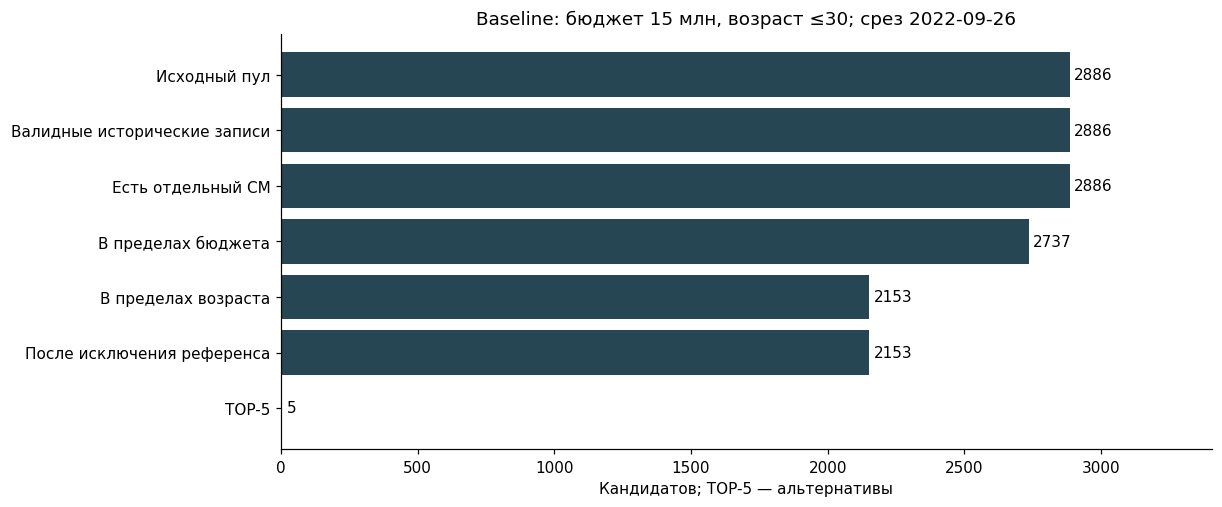

In [4]:
status_counts=audit.status.value_counts()
display(status_counts.to_frame("players"))
all_valid = len(players)-int(audit.status.isin(["invalid_required_value","invalid_historical_date"]).sum())
after_cm=all_valid-int(audit.status.eq("not_cm").sum())
after_budget=after_cm-int(audit.status.eq("over_budget").sum())
after_age=after_budget-int(audit.status.eq("over_age").sum())
after_exclusion=after_age-int(audit.status.eq("excluded_reference").sum())
assert after_exclusion==len(eligible)
funnel=pd.DataFrame({"stage":["Исходный пул","Валидные исторические записи","Есть отдельный CM","В пределах бюджета","В пределах возраста","После исключения референса",f"TOP-{TOP_K}"],
                     "players":[len(players),all_valid,after_cm,after_budget,after_age,after_exclusion,len(top)]})
fig,ax=plt.subplots(figsize=(11,4.5),layout="constrained")
ax.barh(funnel.stage,funnel.players,color=["#264653"]*6+["#2a9d8f"])
ax.invert_yaxis();ax.set_xlim(0,len(players)*1.18)
ax.set(title=f"Baseline: бюджет {BUDGET/1e6:g} млн, возраст ≤{MAX_AGE:g}; срез {CUTOFF}",xlabel=f"Кандидатов; TOP-{TOP_K} — альтернативы")
for i,n in enumerate(funnel.players):ax.text(n+15,i,str(n),va="center")
show(fig,"01_baseline_filter_funnel")


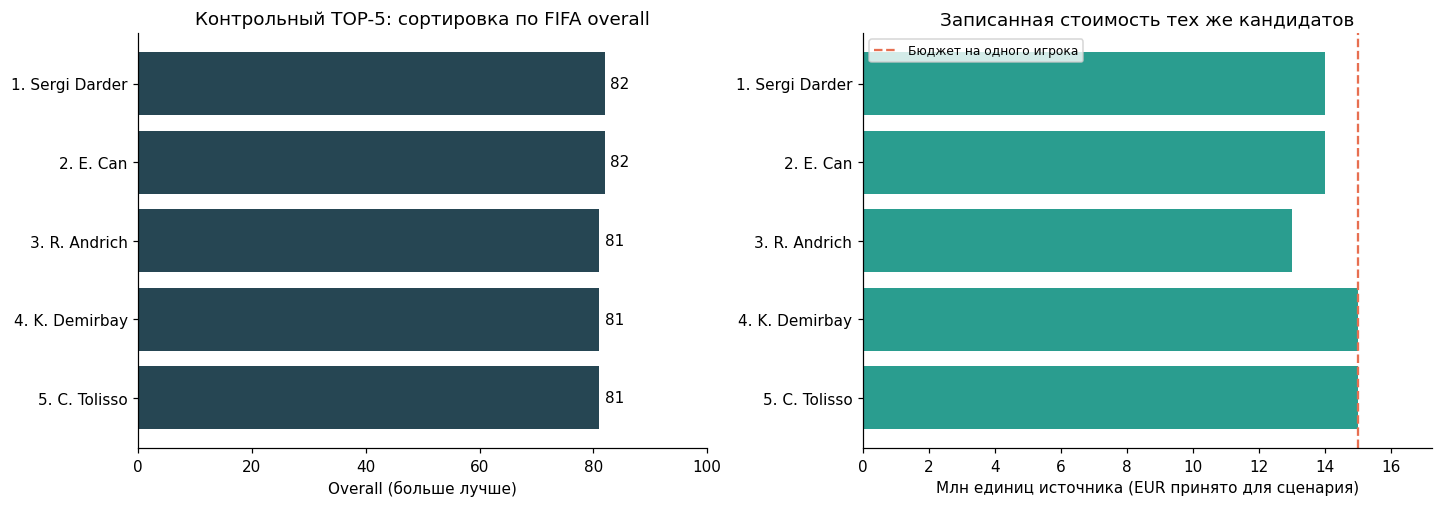

In [5]:
fig,axes=plt.subplots(1,2,figsize=(13,4.5),layout="constrained")
if len(top):
    labels=[f"{rank}. {name}" for rank,name in zip(top.baseline_rank,top.short_name)]
    axes[0].barh(labels,top.overall,color="#264653");axes[0].invert_yaxis();axes[0].set_xlim(0,100)
    axes[0].set(title=f"Контрольный TOP-{TOP_K}: сортировка по FIFA overall",xlabel="Overall (больше лучше)")
    for i,n in enumerate(top.overall):axes[0].text(n+1,i,str(int(n)),va="center")
    axes[1].barh(labels,top.tm_market_value/1e6,color="#2a9d8f");axes[1].invert_yaxis()
    axes[1].axvline(BUDGET/1e6,color="#e76f51",linestyle="--",label="Бюджет на одного игрока")
    axes[1].set_xlim(0,BUDGET/1e6*1.15)
    axes[1].set(title="Записанная стоимость тех же кандидатов",xlabel="Млн единиц источника (EUR принято для сценария)")
    axes[1].legend(fontsize=8)
else:
    for ax in axes:ax.axis("off");ax.text(.5,.5,"Подходящие игроки отсутствуют",ha="center")
show(fig,"02_baseline_top5")


### 3. Чувствительность к бюджету и возрасту

Меняем только доступные клубу ограничения. Сам алгоритм и tie-break не меняются. Это описание работы контрольной системы, а не подбор параметров по test и не доказательство превосходства над ML.


,budget,max_age,eligible,returned,top_mean_overall
0,5000000,25,1126,5,75.0
1,5000000,28,1668,5,77.2
2,5000000,30,1941,5,78.2
3,5000000,32,2190,5,78.8
4,5000000,35,2410,5,80.2
5,10000000,25,1202,5,76.6
6,10000000,28,1794,5,78.4
7,10000000,30,2089,5,79.0
8,10000000,32,2353,5,80.8
9,10000000,35,2579,5,82.6


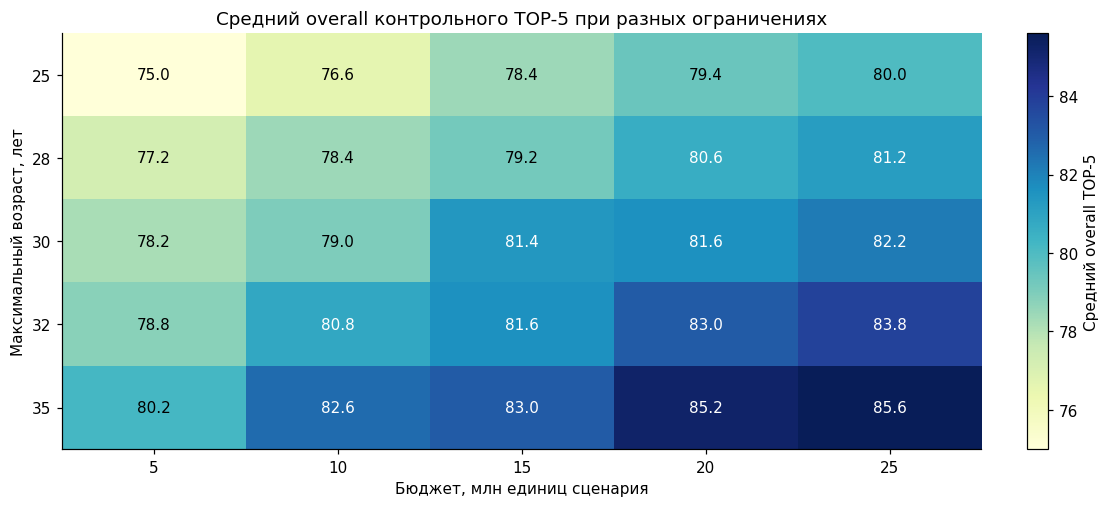

In [6]:
sensitivity=[]
for budget in [5_000_000,10_000_000,15_000_000,20_000_000,25_000_000]:
    for age in [25,28,30,32,35]:
        settings=dict(pool_params,max_value=budget,max_age=age)
        available,_=build_eligible_pool(players,**settings)
        chosen=select_baseline(players,top_k=TOP_K,**settings)
        sensitivity.append({"budget":budget,"max_age":age,"eligible":len(available),"returned":len(chosen),
                            "top_mean_overall":float(chosen.overall.mean()) if len(chosen) else np.nan})
sensitivity=pd.DataFrame(sensitivity)
display(sensitivity)
matrix=sensitivity.pivot(index="max_age",columns="budget",values="top_mean_overall")
fig,ax=plt.subplots(figsize=(10,4.5),layout="constrained")
im=ax.imshow(matrix,aspect="auto",cmap="YlGnBu")
ax.set_xticks(range(len(matrix.columns)),[f"{b/1e6:g}" for b in matrix.columns]);ax.set_yticks(range(len(matrix.index)),matrix.index)
for i in range(len(matrix.index)):
    for j in range(len(matrix.columns)):
        ax.text(j,i,f"{matrix.iloc[i,j]:.1f}",ha="center",va="center",color="white" if matrix.iloc[i,j]>matrix.to_numpy().mean() else "black")
ax.set(title=f"Средний overall контрольного TOP-{TOP_K} при разных ограничениях",xlabel="Бюджет, млн единиц сценария",ylabel="Максимальный возраст, лет")
fig.colorbar(im,ax=ax,label="Средний overall TOP-5")
show(fig,"03_baseline_sensitivity")


### 4. Проверки и условия честного сравнения с ML

Baseline уже является готовой контрольной системой. Будущая ML-рекомендация должна использовать:

- тот же исходный срез, поле цены, правила CM/возраста/бюджета и свежести оценки;
- **тот же список eligible IDs**, а не более удобную подвыборку;
- одинаковое исключение самого референса, если сравнение делается для выбранного игрока;
- одинаковый TOP-k. Baseline ранжирует по overall, ML — по своей заранее определённой функции.

Основная демонстрация использует весь очищенный пул Step 2, без обучения. Для офлайн-сценария test-референс → train-галерея дополнительно сохраняется контрольный TOP-5 только среди train из Step 3. Сравнивать ML train-галерею с baseline полного пула нельзя.

До оценки превосходства необходимо определить независимый критерий. Высокое сходство по тем же признакам, которые использует ML, само по себе не доказывает более успешный трансфер. Test уже использован в EDA; не называем его нетронутым финальным тестом.


In [7]:
shuffled=select_baseline(players.sample(frac=1,random_state=42),**PARAMS)
modified=players.copy()
for column in ["attacking_short_passing","mentality_vision","potential","similarity","predicted_value"]:
    modified[column]=np.arange(len(modified))[::-1]*1000
assert select_baseline(modified,**PARAMS).fifa_id.tolist()==top.fifa_id.tolist()
assert shuffled.fifa_id.tolist()==top.fifa_id.tolist()
assert select_baseline(players,max_value=0,max_age=MAX_AGE,cutoff=CUTOFF).empty

split_path=ROOT/"data/processed/features/player_split.csv"
features_manifest=json.loads((ROOT/"data/processed/features/feature_manifest.json").read_text(encoding="utf-8"))
assert sha(split_path)==features_manifest["outputs"]["player_split.csv"]["sha256"]
assert features_manifest["input_sha256"]==manifest["sha256"]
split=pd.read_csv(split_path,dtype={"fifa_id":str,"tm_id":str})
assert split.fifa_id.is_unique and set(split.fifa_id)==set(players.fifa_id)
assert split.split.isin(["train","test"]).all()
gallery=players.loc[players.fifa_id.isin(split.loc[split.split.eq("train"),"fifa_id"])].copy()
gallery_pool,gallery_audit=build_eligible_pool(gallery,**pool_params)
gallery_top=select_baseline(gallery,**PARAMS)
display(gallery_top[columns].round({"age_at_cutoff":2}))

checks={
 "correct_five_step_algorithm":top.fifa_id.tolist()==manual.fifa_id.tolist(),
 "at_most_top_k":len(top)==min(TOP_K,len(eligible)),
 "unique_players":top.fifa_id.is_unique,
 "exact_cm_token":top.player_positions_normalized.str.split("|").map(lambda p:"CM" in p).all(),
 "individual_budget":top.tm_market_value.le(BUDGET).all(),
 "maximum_fractional_age":top.age_at_cutoff.le(MAX_AGE).all(),
 "no_future_prices":top.market_value_date.le(CUTOFF).all(),
 "overall_descending":top.overall.is_monotonic_decreasing,
 "deterministic_under_shuffle":top.fifa_id.tolist()==shuffled.fifa_id.tolist(),
 "all_selected_ids_eligible":set(top.fifa_id).issubset(eligible.fifa_id),
 "audit_reconciles":len(audit)==len(players) and int(audit.status.eq("eligible").sum())==len(eligible),
 "train_gallery_only":set(gallery_top.fifa_id).issubset(split.loc[split.split.eq("train"),"fifa_id"]),
}
assert all(checks.values()),{k:v for k,v in checks.items() if not v}
display(pd.DataFrame({"check":checks.keys(),"passed":checks.values()}))
print("Additional boundary tests: python -m pytest -q tests/test_baseline.py")


Additional boundary tests: python -m pytest -q tests/test_baseline.py


,baseline_rank,fifa_id,short_name,club_name,player_positions_normalized,age_at_cutoff,overall,tm_market_value,market_value_date
0,1,202648,Sergi Darder,Espanyol,CM|CDM|CAM,28.76,82,14000000.0,2022-06-02
1,2,208333,E. Can,Borussia Dortmund,CM|CB|CDM,28.70,82,14000000.0,2022-09-20
2,3,212242,R. Andrich,Bayer 04 Leverkusen,CDM|CM,28.01,81,13000000.0,2022-06-08
3,4,211748,K. Demirbay,Bayer 04 Leverkusen,CM|CDM|CAM,29.23,81,15000000.0,2022-06-08
4,5,219683,C. Tolisso,Olympique Lyonnais,CM|CDM,28.15,81,15000000.0,2022-06-08


,check,passed
0,correct_five_step_algorithm,True
1,at_most_top_k,True
2,unique_players,True
3,exact_cm_token,True
4,individual_budget,True
5,maximum_fractional_age,True
6,no_future_prices,True
7,overall_descending,True
8,deterministic_under_shuffle,True
9,all_selected_ids_eligible,True


### 5. Фиксация контрольного результата

Экспортируем рейтинг, все допустимые ID, причины исключения, таблицу чувствительности и протокол сравнения. Цена — только фильтр и tie-break; overall — единственный основной критерий ранжирования. Других обучаемых весов нет.

Списки игроков сохраняются локально в gitignored `data/processed/baseline/`. Общий протокол и PNG/SVG графики — в `reports/baseline/`. Результат исторический и ограничен покрытием FIFA–TM, не является актуальным трансферным предложением.


In [8]:
top[columns].to_csv(OUT/"baseline_top5.csv",index=False)
eligible.to_csv(OUT/"eligible_pool_full.csv",index=False)
audit.to_csv(OUT/"eligibility_audit.csv",index=False)
gallery_top[columns].to_csv(OUT/"baseline_top5_train_gallery.csv",index=False)
gallery_pool.to_csv(OUT/"eligible_pool_train_gallery.csv",index=False)
sensitivity.to_csv(REPORT/"parameter_sensitivity.csv",index=False)
funnel.to_csv(REPORT/"filter_funnel.csv",index=False)
protocol={
 "algorithm":"CM + individual budget + maximum age; overall descending; lower value then string fifa_id for ties",
 "version":"baseline-v1", "cutoff":CUTOFF,"max_value":BUDGET,"max_age":MAX_AGE,"top_k":TOP_K,
 "age_semantics":"fractional years at cutoff <= max_age", "max_value_age_days":MAX_VALUE_AGE_DAYS,
 "price_column":"tm_market_value","currency_assumption":CURRENCY_ASSUMPTION,"currency_status":CURRENCY_STATUS,
 "budget_semantics":"per alternative player, not sum across TOP-5", "input_sha256":sha(source),
 "excluded_fifa_ids":EXCLUDED_FIFA_IDS,"ranking_columns":list(RANK_COLUMNS),"ranking_ascending":[False,True,True],
 "full_pool":{"source_rows":len(players),"eligible_rows":len(eligible),"returned_rows":len(top),"eligible_ids_sha256":ids_hash(eligible.fifa_id)},
 "train_gallery":{"source_rows":len(gallery),"eligible_rows":len(gallery_pool),"returned_rows":len(gallery_top),"eligible_ids_sha256":ids_hash(gallery_pool.fifa_id)},
 "validation":{k:bool(v) for k,v in checks.items()},"figures":figures,
 "comparison_rule":"ML and baseline must use identical eligible IDs, budget, age, cutoff, top_k and excluded reference IDs",
 "holdout_status":"already_explored_in_EDA_not_untouched_final_test",
}
(REPORT/"baseline_protocol.json").write_text(json.dumps(protocol,ensure_ascii=False,indent=2),encoding="utf-8")
loaded=pd.read_csv(OUT/"baseline_top5.csv",dtype={"fifa_id":str})
assert loaded.fifa_id.tolist()==top.fifa_id.tolist()
assert loaded.overall.tolist()==top.overall.tolist()
assert np.allclose(loaded.tm_market_value,top.tm_market_value)
assert ids_hash(pd.read_csv(OUT/"eligible_pool_full.csv",dtype={"fifa_id":str}).fifa_id)==protocol["full_pool"]["eligible_ids_sha256"]
display(Markdown(f"**Контрольная система готова.** Из {len(players):,} игроков допустимы {len(eligible):,}; возвращено {len(top)}. "
                 f"Бюджет: {BUDGET/1e6:g} млн ({CURRENCY_ASSUMPTION} как сценарное допущение); возраст ≤{MAX_AGE:g} лет. "
                 "Рейтинг и протокол сохранены. ML-сравнение здесь не выполнялось."))


**Контрольная система готова.** Из 2,886 игроков допустимы 2,153; возвращено 5. Бюджет: 15 млн (EUR как сценарное допущение); возраст ≤30 лет. Рейтинг и протокол сохранены. ML-сравнение здесь не выполнялось.